In [1]:
import warnings
warnings.filterwarnings("ignore")   # hide the warnings yfinance prints

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm

Stock Dataset for each listed stock


In [2]:
# ---- Settings ----
TICKERS = ["AAPL", "MSFT", "JPM", "GS", "XOM", "JNJ", "UNH", "KO",
           "PG", "WMT", "AMZN", "HD", "CAT", "BA"]   # large companies across sectors
START = "2010-07-01"        # all tickers trade over the full period
END = "2022-12-31"          # train through 2022, test 2023 onward
DATA_END = "2026-11-07"
ANN = np.sqrt(252) * 100    # daily std -> annualized % (same units as VIX)

#CLosing prices normalized
def normalize_dates(ticker):
    """Remove timezones and times so dates match across all tickers."""
    prices = yf.Ticker(ticker).history(start=START, end=DATA_END)["Close"]
    dates = pd.DatetimeIndex(pd.to_datetime(prices.index))
    if dates.tz is not None:
        dates = dates.tz_localize(None)
    prices.index = dates.normalize()
    return prices



# Calculating past volatility and volatility for next week
def build_stock_data(ticker):
    """Predictors and target for one ticker. Each row is one trading day."""
    ret = normalize_dates(ticker).pct_change() # daily return

    df = pd.DataFrame(index=ret.index)
    df["vol_5d"] = ret.rolling(5).std() * ANN # week
    df["vol_21d"] = ret.rolling(21).std() * ANN # month
    df["vol_63d"] = ret.rolling(63).std() * ANN # quarter
    # Target volatility next 5 days
    df["fwd_vol"] = ret.rolling(5).std().shift(-5) * ANN
    return df.dropna()


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
c:\User

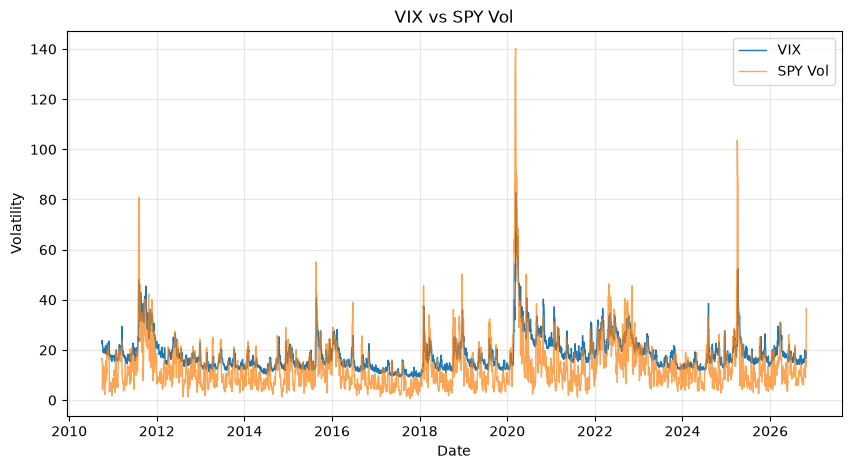

In [3]:
# Spy and VIX
vix = normalize_dates("^VIX") # market forecast volatility
spy_df = build_stock_data("SPY")
spy_df["vix"] = vix # add VIX to spy data
spy_df = spy_df.dropna()

# Plot 1 Vix vs. Actual Spy volatility next week

fig, ax = plt.subplots(figsize=(10,5))
ax.plot(spy_df.index, spy_df["vix"], lw=1, label="VIX")
ax.plot(spy_df.index, spy_df["fwd_vol"], lw=1, alpha=0.7, label="SPY Vol")
ax.set_xlabel("Date")
ax.set_ylabel("Volatility")
ax.set_title("VIX vs SPY Vol")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Which Predictor Best Lines up with the Target

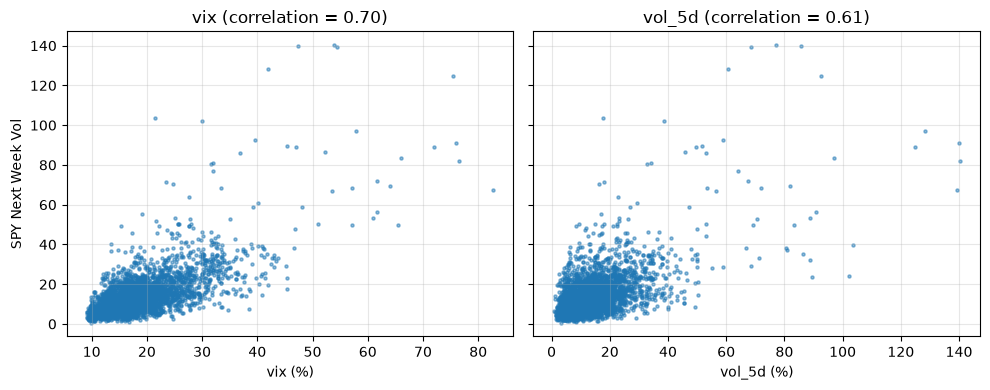

In [4]:
fig, axes = plt.subplots(1,2, figsize=(10,4), sharey=True)
for ax, col in zip(axes, ["vix", "vol_5d"]):
    r = spy_df[col].corr(spy_df["fwd_vol"])
    ax.scatter(spy_df[col], spy_df["fwd_vol"], s=5, alpha=0.5)
    ax.set_title(f"{col} (correlation = {r:.2f})")
    ax.set_xlabel(f"{col} (%)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("SPY Next Week Vol")
plt.tight_layout()
plt.show()

Data for 14 Stocks

In [5]:
stock_data = {}
for t in TICKERS:
    stock_data[t] = build_stock_data(t)
    print(f"{t}: {len(stock_data[t])} rows")

c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

AAPL: 4046 rows


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

MSFT: 4046 rows


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

JPM: 4046 rows


... (17 outputs left out)

HD: 4046 rows


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

CAT: 4046 rows
BA: 4046 rows


c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

Combined data for stocks

In [6]:
combined = pd.DataFrame(index=spy_df.index)

# Spy's volatility (baseline) and Vix (benchmark)
combined["spy_vol_5d"] = spy_df["vol_5d"]
combined["spy_vol_21d"] = spy_df["vol_21d"]
combined["spy_vol_63d"] = spy_df["vol_63d"]
combined["vix"] = spy_df["vix"]

#  Past volatility for each stock
for t in TICKERS:
    for w in ["5d", "21d", "63d"]:
        combined[f"{t}_vol_{w}"] = stock_data[t][f"vol_{w}"]
combined["target"] = spy_df["fwd_vol"]
combined = combined.dropna()
print(combined.shape)

(4046, 47)


Train and Test Split

In [7]:
train = combined.loc[combined.index <= END] # 2010-2022
test = combined.loc[combined.index > END]   # 2023 +

#Dropping last 5 training dayys: targets use 2023 prices which isn't in the test period
train = train.iloc[:-5]

X_train = train.drop(columns=["target"])
y_train = train["target"]
X_test = test.drop(columns=["target"])
y_test = test["target"]


#Column groups used by the models
BASELINE_COLS = ["spy_vol_5d", "spy_vol_21d", "spy_vol_63d"]
STOCK_COLS = [f"{t}_vol_{w}" for t in TICKERS for w in ["5d", "21d", "63d"]]
ALL_COLS = BASELINE_COLS + STOCK_COLS # 45 predictors

print(f"Training rows: {len(train)} ({train.index[0].date()} to {train.index[-1].date()})")
print(f"Test rows: {len(test)} ({test.index[0].date()} to {test.index[-1].date()})")

Training rows: 3080 (2010-09-30 to 2022-12-22)
Test rows: 961 (2023-01-03 to 2026-10-30)


Summary of target

In [8]:
# Volatile week: top 25% of training weeks
threshold = y_train.quantile(0.75)
spy_volatile = (combined["target"] > threshold).astype(int) # classification 
target_summary = pd.DataFrame({
    "mean %": [y_train.mean(), y_test.mean()],
    "median %": [y_train.median(), y_test.median()],
    "skew": [y_train.skew(), y_test.skew()],
    "volatile weeks %": [spy_volatile[train.index].mean() * 100,
                         spy_volatile[test.index].mean() * 100],
}, index=["Train (2010-2022)", "Test (2023+)"]).round(2)

print(f"Volatile-week threshold: {threshold:.2f}%")
target_summary

Volatile-week threshold: 17.24%


,mean %,median %,skew,volatile weeks %
Train (2010-2022),13.79,10.95,3.86,25.00
Test (2023+),12.64,11.33,5.39,17.59


Which Stocks past weeks tracks SPY's volatility

HD      0.568
JPM     0.534
PG      0.529
JNJ     0.525
XOM     0.516
BA      0.514
KO      0.514
MSFT    0.502
GS      0.500
UNH     0.491
CAT     0.470
AAPL    0.467
WMT     0.398
AMZN    0.344
dtype: float64


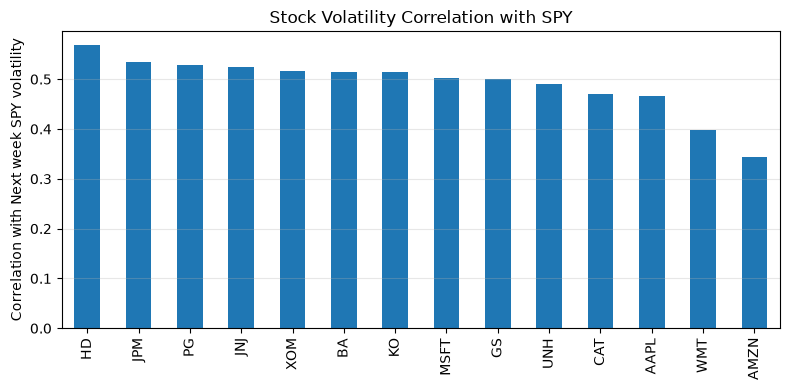

In [21]:
# Uses Training Data Only test period is unseen
stock_corr = pd.Series(
    {t: train[f"{t}_vol_5d"].corr(y_train) for t in TICKERS}).sort_values(ascending=False)

print(stock_corr.round(3))
stock_corr.plot(kind="bar", figsize=(8,4))

plt.ylabel("Correlation with Next week SPY volatility")
plt.title("Stock Volatility Correlation with SPY")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

How Correlated ae the stocks with each other

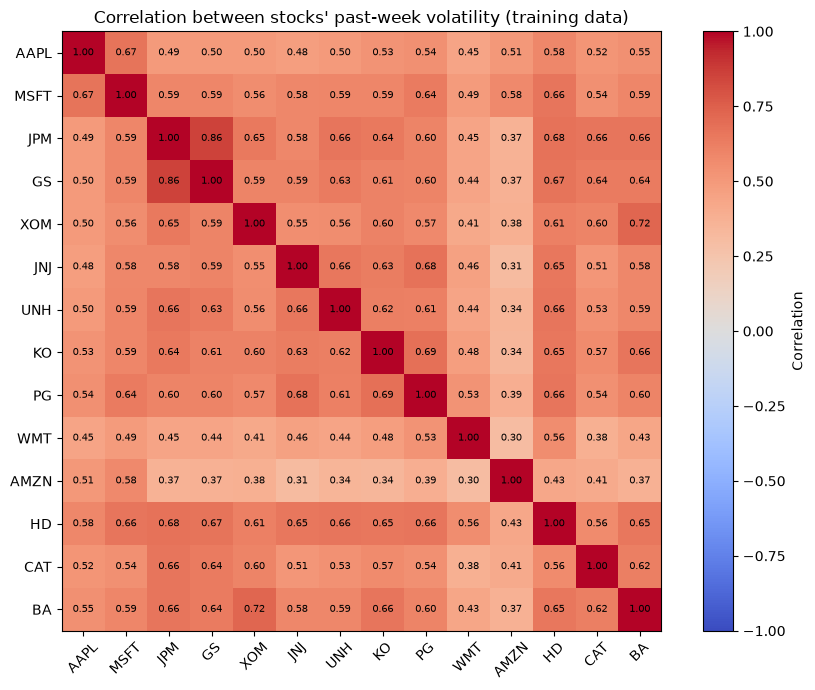

In [23]:
corr_matrix = train[[f"{t}_vol_5d" for t in TICKERS]].corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(TICKERS)), TICKERS, rotation=45)
plt.yticks(range(len(TICKERS)), TICKERS)

# Write the value in each square
for i in range(len(TICKERS)):
    for j in range(len(TICKERS)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)

plt.title("Correlation between stocks' past-week volatility (training data)")
plt.tight_layout()
plt.show()

Helper Functions and Linear Regression: We fit a linear regression model on the training data using columns and return the test MSE,R^2, and fitted model       


In [11]:
def fit_and_score(cols):
    """Fitting linear regresion on training data using cols. Returns test MSE, test R2 and model."""
    model = LinearRegression().fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    scores =  {"test_MSE": mean_squared_error(y_test, pred),
            "test_R2": r2_score(y_test, pred)
            }
    return scores, model

def pct_reduct(mse): 
    """Percent reduction vs baseline. Positive is better than baseline"""
    base = baseline_scores["test_MSE"]
    return (base - mse)/base*100

Benchmark and Baseline for VIX

In [24]:
# Naive guess, no fitting: next week's volatility = last week's
naive_scores = {"test_MSE": mean_squared_error(y_test, X_test["spy_vol_5d"]),
                "test_R2": r2_score(y_test, X_test["spy_vol_5d"])}

baseline_scores, baseline_model = fit_and_score(BASELINE_COLS)
vix_scores, vix_model = fit_and_score(BASELINE_COLS + ["vix"])

benchmark_table = pd.DataFrame({
    "Naive (next week = last week)": naive_scores,
    "Baseline (SPY past vol)": baseline_scores,
    "VIX benchmark (SPY past vol + VIX)": vix_scores,
}).T.round(3)
display(benchmark_table)

,test_MSE,test_R2
Naive (next week = last week),84.804,-0.202
Baseline (SPY past vol),62.466,0.115
VIX benchmark (SPY past vol + VIX),48.868,0.308


One Stock at a Time

,test_MSE,test_R2,MSE_reduction_%
JNJ,59.006,0.164,5.539
KO,61.858,0.123,0.972
PG,61.911,0.123,0.888
XOM,61.990,0.122,0.762
MSFT,62.505,0.114,-0.063
AMZN,62.641,0.112,-0.281
BA,62.965,0.108,-0.799
WMT,62.977,0.108,-0.818
AAPL,63.108,0.106,-1.029
CAT,63.183,0.105,-1.148


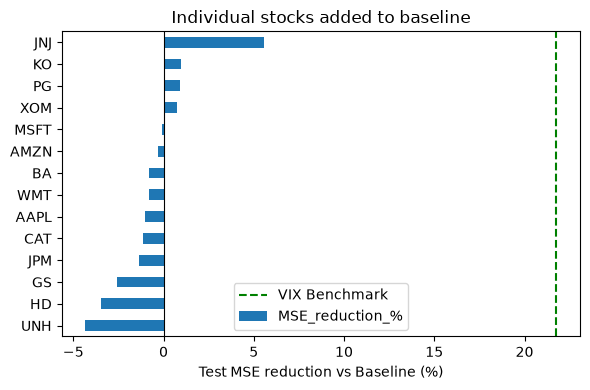

Best Stock: JNJ


In [25]:
rows = []


for t in TICKERS:
    # Baseline + this one stock's past week, month, and quarter
    cols = BASELINE_COLS +[
        f"{t}_vol_5d",
        f"{t}_vol_21d",
        f"{t}_vol_63d"
    ]

    scores, _ = fit_and_score(cols)
    scores["MSE_reduction_%"] = pct_reduct(scores["test_MSE"])
    rows.append(pd.Series(scores, name=t))

# Ranking stocks on improvement
stock_rank = pd.DataFrame(rows)
stock_rank = stock_rank.sort_values("MSE_reduction_%", ascending=False)
display(stock_rank.round(3))

# Comparing stock improvement with VIX
vix_reduction = pct_reduct(vix_scores["test_MSE"])

stock_rank['MSE_reduction_%'].sort_values().plot(kind="barh", figsize=(6,4))
plt.axvline(vix_reduction, color='green', linestyle='--', label= 'VIX Benchmark')
plt.axvline(0, color='black', lw=0.8)

plt.xlabel("Test MSE reduction vs Baseline (%)")
plt.title("Individual stocks added to baseline")
plt.legend()
plt.tight_layout()
plt.show()

# Best individual stock
best_stock = stock_rank.index[0]
print("Best Stock:",best_stock)

Linear regression on all 14 stocks

In [26]:
allstock_scores, allstock_model = fit_and_score(ALL_COLS)
train_R2 = allstock_model.score(X_train[ALL_COLS], y_train)   # .score gives R^2

# A big gap between training and test R^2 is a sign of overfitting
print(f"Train R^2 = {train_R2:.3f}, test R^2 = {allstock_scores['test_R2']:.3f}")
print(f"Test MSE reduction vs. baseline: {pct_reduct(allstock_scores['test_MSE']):.1f}%")



Train R^2 = 0.486, test R^2 = -0.137
Test MSE reduction vs. baseline: -28.4%


Lasso with CV

In [33]:
# TimeSeriesSplit is K-fold CV for time series: each fold trains on the past
# and validates on the future. gap=5 skips the 5 days whose targets overlap.
tscv = TimeSeriesSplit(n_splits=5, gap=5)
ALPHAS = np.logspace(-3, 1.5, 60)     # lambda values to try (sklearn calls it alpha)


# Finding best lambda for LASSO
def lasso_cv(cols):
    cv_mse = []
    for a in ALPHAS:
        pipe = make_pipeline(
            StandardScaler(),
            Lasso(alpha=a, max_iter=100_000)
        )
        mse = -cross_val_score(pipe, X_train[cols], y_train,
                               cv=tscv, scoring="neg_mean_squared_error")
        cv_mse.append(mse.mean())
    best_alpha = ALPHAS[np.argmin(cv_mse)]

    #Training final model
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_train[cols])

    model = Lasso(alpha=best_alpha, max_iter=100_000)
    model.fit(X_scaled, y_train)
    return model, scaler, best_alpha,cv_mse

# Calculating test MSE and R2
def lasso_test_scores(model, scaler, cols):
    X_scaled = scaler.transform(X_test[cols])
    y_hat = model.predict(X_scaled)

    return {
        "test_MSE": mean_squared_error(y_test, y_hat),
        "test_R2": r2_score(y_test, y_hat)
    }

# Fit LASSO with all stocks
lasso_model, lasso_scaler, lasso_alpha, lasso_cv_mse = lasso_cv(ALL_COLS)
lasso_scores = lasso_test_scores(lasso_model, lasso_scaler, ALL_COLS)

print(f"Best lambda: {lasso_alpha:.4f}")
print(f"LASSO test MSE: {lasso_scores['test_MSE']:.2f}")
print(f"LASSO test R2: {lasso_scores['test_R2']:.3f}")
print(f"MSE reduction: {pct_reduct(lasso_scores['test_MSE']):.1f}%")


Best lambda: 0.5569
LASSO test MSE: 58.74
LASSO test R2: 0.168
MSE reduction: 6.0%


Will LASSO continue to pick the same stocks?


In [34]:
# Check which stocks LASSO selects across each CV fold
times_kept = pd.Series(0, index=TICKERS)

for k, (tr_idx, _) in enumerate(tscv.split(X_train),start=1):
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_train[ALL_COLS].iloc[tr_idx])

    model = Lasso(alpha=lasso_alpha, max_iter=100_000)
    model.fit(X_tr, y_train.iloc[tr_idx])

    coefs = pd.Series(model.coef_, index=ALL_COLS)

    kept = [
        t for t in TICKERS
        if (coefs.filter(regex=f"^{t}_")!=0).any()
    ]
    times_kept[kept] += 1
    print(f"Fold {k}: {kept}")

print("\nTimes kept:")
print(times_kept.sort_values(ascending=False))

Fold 1: ['MSFT', 'XOM', 'UNH', 'KO', 'CAT', 'BA']
Fold 2: ['JPM', 'XOM', 'UNH', 'HD', 'CAT']
Fold 3: ['XOM', 'UNH', 'CAT', 'BA']
Fold 4: ['AAPL', 'XOM', 'UNH', 'CAT', 'BA']
Fold 5: ['AAPL', 'XOM', 'JNJ', 'UNH', 'PG', 'HD']

Times kept:
XOM     5
UNH     5
CAT     4
BA      3
HD      2
AAPL    2
KO      1
JNJ     1
JPM     1
MSFT    1
PG      1
GS      0
WMT     0
AMZN    0
dtype: int64


Model with every column, stock, and vix included

In [36]:
# LASSO with VIX and all stocks 
EVERYTHING_COLS = ALL_COLS + ["vix"]

every_model, every_scaler, every_alpha, _ = lasso_cv(EVERYTHING_COLS)

every_scores = lasso_test_scores(every_model, every_scaler, EVERYTHING_COLS)
every_coefs = pd.Series(every_model.coef_, index=EVERYTHING_COLS)

print(f"Best Lambda: {every_alpha:.4f}")
print(f"Test MSE : {every_scores['test_MSE']:.2f}")
print(f"Test R2: {every_scores['test_R2']:.3f}")
print(f"MSE reduction: {pct_reduct(every_scores['test_MSE']):.1f}%")

print(f"VIX coef: {every_coefs['vix']:.3f}")

# Stocks selected with VIX
vix_stocks = [
    t for t in TICKERS 
    if (every_coefs.filter(regex=f"^{t}_") != 0).any()
]
print("Stocks kept with VIX:", vix_stocks)

Best Lambda: 0.2759
Test MSE : 47.33
Test R2: 0.329
MSE reduction: 24.2%
VIX coef: 7.134
Stocks kept with VIX: ['AAPL', 'JPM', 'GS', 'XOM', 'JNJ', 'UNH', 'PG', 'WMT', 'HD', 'BA']


Comparison of the regression models

,test_MSE,test_R2,MSE_reduction
Naive (next week = last week),84.804,-0.202,-35.761
Baseline (SPY past vol),62.466,0.115,0.000
Best single stock,59.006,0.164,5.539
All stocks with linear regression,80.227,-0.137,-28.434
All stocks with LASSO,58.737,0.168,5.970
VIX benchmark,48.868,0.308,21.768
"All stocks + VIX, LASSO",47.330,0.329,24.231


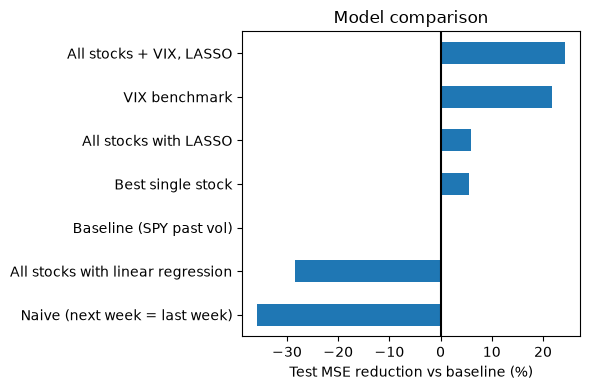

Lowest Test MSE: All stocks + VIX, LASSO
Highest Test R2: All stocks + VIX, LASSO


In [38]:
best_cols = BASELINE_COLS + [
    f"{best_stock}_vol_5d",
    f"{best_stock}_vol_21d",
    f"{best_stock}_vol_63d"
]
best_scores, best_model = fit_and_score(best_cols)

comp_table = pd.DataFrame({
    "Naive (next week = last week)": naive_scores,
    "Baseline (SPY past vol)": baseline_scores,
    "Best single stock": best_scores,
    "All stocks with linear regression": allstock_scores,
    "All stocks with LASSO": lasso_scores,
    "VIX benchmark": vix_scores,
    "All stocks + VIX, LASSO": every_scores,
}).T
baseline_mse = baseline_scores["test_MSE"]
comp_table["MSE_reduction"] = (baseline_mse - comp_table["test_MSE"])/baseline_mse*100
display(comp_table.round(3))

#plot model comparison
comp_table["MSE_reduction"].sort_values().plot(kind="barh", figsize=(6,4))
plt.axvline(0, color="black")
plt.xlabel("Test MSE reduction vs baseline (%)")
plt.title("Model comparison")
plt.tight_layout()
plt.show()

print("Lowest Test MSE:", comp_table["test_MSE"].idxmin())
print("Highest Test R2:", comp_table["test_R2"].idxmax())

## Results

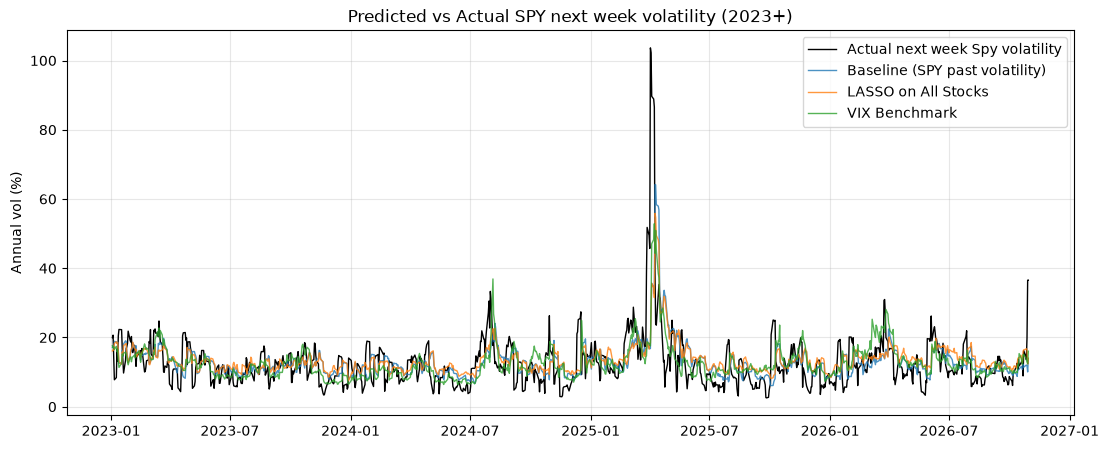

In [47]:
# Running predictions for the test period (2023 +) from the trained models

preds = pd.DataFrame({
    "Actual": y_test,
    "Baseline (SPY past volatility)": baseline_model.predict(X_test[BASELINE_COLS]),
    "LASSO on All Stocks": lasso_model.predict(lasso_scaler.transform(X_test[ALL_COLS])),
    "VIX Benchmark": vix_model.predict(X_test[BASELINE_COLS + ["vix"]])
    
}, index=y_test.index)

#Predicted vs actual plot
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(preds.index, preds["Actual"], lw=1, color="black", label="Actual next week Spy volatility")
for col in ["Baseline (SPY past volatility)", "LASSO on All Stocks", "VIX Benchmark"]:
    ax.plot(preds.index, preds[col], lw=1, alpha=0.8, label=col)
ax.set_ylabel("Annual vol (%)")
ax.set_title("Predicted vs Actual SPY next week volatility (2023+)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# April 2025 Spike

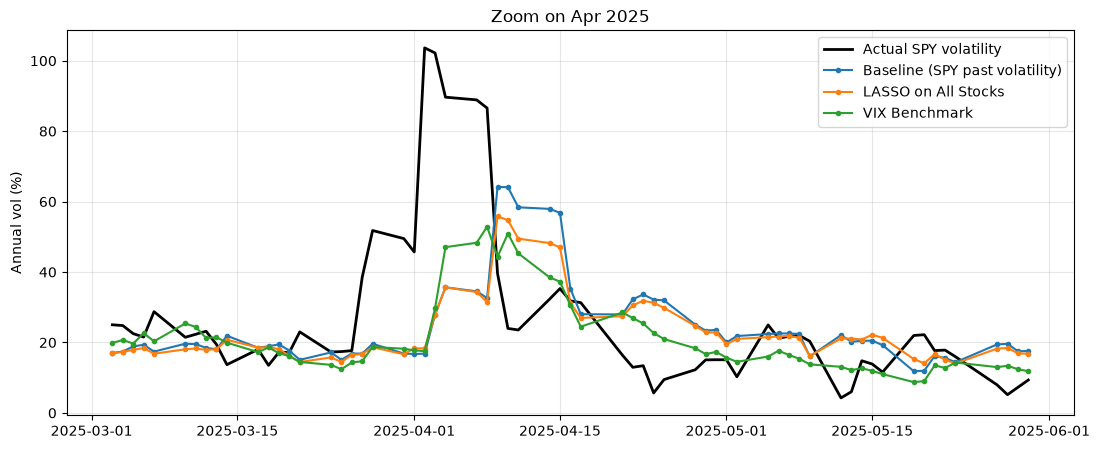

Peak day: 2025-04-02
Actual                            103.65
Baseline (SPY past volatility)     16.82
LASSO on All Stocks                18.33
VIX Benchmark                      17.55
Name: 2025-04-02 00:00:00, dtype: float64


In [48]:
# focusing in on between March and May 2025
spike = preds.loc["2025-03":"2025-05"]

fig, ax = plt.subplots(figsize=(13,5))

ax.plot(spike.index, spike["Actual"], lw=2, color="black", label="Actual SPY volatility")

for col in ["Baseline (SPY past volatility)", "LASSO on All Stocks", "VIX Benchmark"]:
    ax.plot(spike.index, spike[col], lw=1.5, marker=("."), label=col)
    
ax.set_ylabel("Annual vol (%)")
ax.set_title("Zoom on Apr 2025")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# What each model predicted on the worst day
peak_day = spike["Actual"].idxmax()
print(f"Peak day: {peak_day.date()}")
print(spike.loc[peak_day].round(2))

# Which stocks were the best indicators?


In [46]:
# Using stocks that were kept by LASSO
lasso_coefs = pd.Series(every_model.coef_, index=EVERYTHING_COLS)
keep_stocks = [t for t in TICKERS if (lasso_coefs.filter(regex=f"^{t}_") != 0).any()]

# Comparing stock indicators 
indicators = pd.DataFrame({
    "MSE_reduction_%": stock_rank["MSE_reduction_%"],
    "Kept by LASSO": [t in keep_stocks for t in stock_rank.index],
    "Folds kept": times_kept.reindex(stock_rank.index),
    "Kept_with_VIX": [t in vix_stocks for t in stock_rank.index]
})
indicator_table = indicators.sort_values("MSE_reduction_%", ascending=False)
display(indicator_table.round(3))


,MSE_reduction_%,Kept by LASSO,Folds kept,Kept_with_VIX
JNJ,5.539,True,1,True
KO,0.972,False,1,False
PG,0.888,True,1,True
XOM,0.762,True,5,True
MSFT,-0.063,False,1,False
AMZN,-0.281,False,0,False
BA,-0.799,True,3,True
WMT,-0.818,True,0,True
AAPL,-1.029,True,2,True
CAT,-1.148,False,4,False


# CI for JNJ


In [49]:
# Additional improvement: 
# Using same model as the "best single stock", fit with statsmodes to get p-values and CI
X_best = sm.add_constant(X_train[best_cols])

ols = sm.OLS(y_train, X_best).fit(
    cov_type="HAC",
    cov_kwds={"maxlags":5}
)
print(f"Best individual stock: {best_stock}")
print(ols.summary())

# CI for regression coefficients
print("\n95% CI:")
print(ols.conf_int())

Best individual stock: JNJ
                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.456
Model:                            OLS   Adj. R-squared:                  0.454
Method:                 Least Squares   F-statistic:                     59.22
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           1.25e-69
Time:                        14:31:22   Log-Likelihood:                -10893.
No. Observations:                3080   AIC:                         2.180e+04
Df Residuals:                    3073   BIC:                         2.184e+04
Df Model:                           6                                         
Covariance Type:                  HAC                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           3.5502 

# Volatility targeting strategy

In [50]:
# Hold less SPY when a model predicts high volatility or more when it is low

# SPY's daily % change for test period
spy_ret = normalize_dates("SPY").pct_change()
spy_ret = spy_ret.loc[preds.index]

#Target vol based on the training data
target_vol = y_train.mean()

base_position = np.minimum(target_vol / preds["Baseline (SPY past volatility)"].clip(lower=0.01), 1)

lasso_position = np.minimum(target_vol / preds["LASSO on All Stocks"].clip(lower=0.01), 1)
vix_position = np.minimum(target_vol / preds["VIX Benchmark"].clip(lower=0.01), 1)

#Comparing daily returns of each strategy
strategies = pd.DataFrame(index=preds.index)
strategies["Buy and hold SPY"] = spy_ret
strategies["Baseline sizing"] = base_position.shift(1) * spy_ret
strategies["LASSO sizing"] = lasso_position.shift(1) * spy_ret
strategies["VIX sizing"] = vix_position.shift(1) * spy_ret
strategies = strategies.dropna()

c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\clayh\Downloads\FINAL PROJECT 381\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

Target Volatility: 13.79%
                  total_return_%  annual_vol_%  max_drawdown_%
Buy and hold SPY          108.05         14.86          -18.76
Baseline sizing            92.76         12.61          -13.86
LASSO sizing               94.49         12.56          -13.67
VIX sizing                 87.88         12.24          -13.61


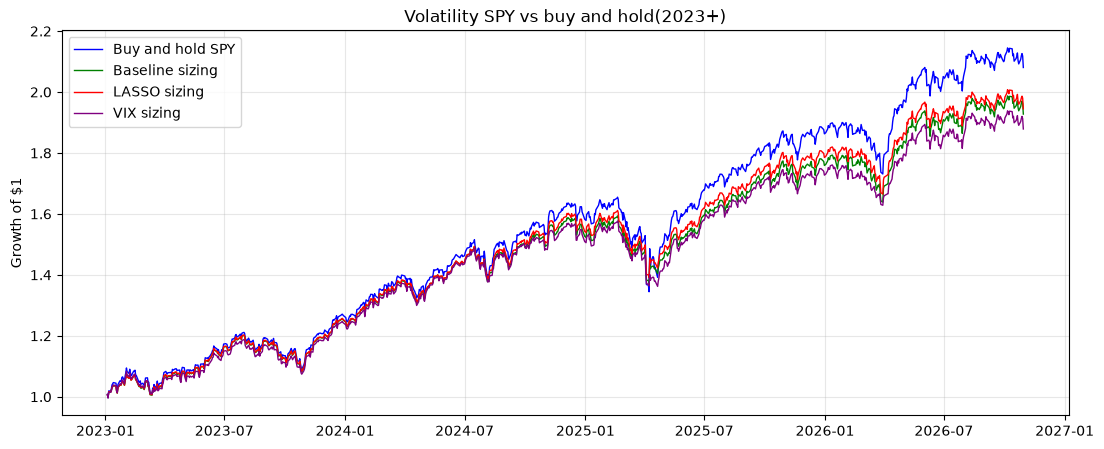


Highest Return: Buy and hold SPY
Lowest Vol: VIX sizing
Lowest Drawdown: Buy and hold SPY


In [51]:
# Compare strategy returns and plot
# growth of $1 for each strategy

growth = (1 + strategies).cumprod()
drawdown = growth / growth.cummax() - 1

strategy_table = pd.DataFrame({
    "total_return_%": (growth.iloc[-1] - 1) * 100,
    "annual_vol_%": strategies.std() * ANN,
    "max_drawdown_%": drawdown.min() * 100,
}).round(2)
print(f"Target Volatility: {target_vol:.2f}%")

print(strategy_table)

# Plot growth of $1
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(growth.index, growth["Buy and hold SPY"], lw = 1, color='blue', label = "Buy and hold SPY")
ax.plot(growth.index, growth["Baseline sizing"], lw = 1, color='green', label = "Baseline sizing")
ax.plot(growth.index, growth["LASSO sizing"], lw = 1, color='red', label = "LASSO sizing")
ax.plot(growth.index, growth["VIX sizing"], lw = 1, color='purple', label = "VIX sizing")
ax.set_ylabel("Growth of $1")
ax.set_title("Volatility SPY vs buy and hold(2023+)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Comparing returns and risks
print("\nHighest Return:", strategy_table["total_return_%"].idxmax())
print("Lowest Vol:", strategy_table["annual_vol_%"].idxmin())
print("Lowest Drawdown:", strategy_table["max_drawdown_%"].idxmin())